<a href="https://colab.research.google.com/github/Komal5578/DWM/blob/main/kmeans_eeg_simple.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# K-Means Clustering on EEG Eye State
**Idea:** K-Means groups similar data points together without using labels. Here we ask it to find 2 groups (eyes open / eyes closed) and then check how well they match the real labels.

## Step 1: Import libraries

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import confusion_matrix, accuracy_score

## Step 2: Load the data
Keep `EEG Eye State.csv` in the same folder as this notebook.

In [3]:
df = pd.read_csv("EEG Eye State.csv")
print(df.shape)
df.head()

(14980, 15)


,AF3,F7,F3,FC5,T7,P7,O1,O2,P8,T8,FC6,F4,F8,AF4,eyeDetection
0,4329.23,4009.23,4289.23,4148.21,4350.26,4586.15,4096.92,4641.03,4222.05,4238.46,4211.28,4280.51,4635.90,4393.85,0
1,4324.62,4004.62,4293.85,4148.72,4342.05,4586.67,4097.44,4638.97,4210.77,4226.67,4207.69,4279.49,4632.82,4384.10,0
2,4327.69,4006.67,4295.38,4156.41,4336.92,4583.59,4096.92,4630.26,4207.69,4222.05,4206.67,4282.05,4628.72,4389.23,0
3,4328.72,4011.79,4296.41,4155.90,4343.59,4582.56,4097.44,4630.77,4217.44,4235.38,4210.77,4287.69,4632.31,4396.41,0
4,4326.15,4011.79,4292.31,4151.28,4347.69,4586.67,4095.90,4627.69,4210.77,4244.10,4212.82,4288.21,4632.82,4398.46,0


## Step 3: Separate features and labels
The labels (`eyeDetection`) are used **only for checking** the result, not for clustering.

In [4]:
X = df.drop("eyeDetection", axis=1)
y = df["eyeDetection"]

## Step 4: Scale the features
K-Means uses distances, so all features must be on the same scale.

In [5]:
X_scaled = StandardScaler().fit_transform(X)

## Step 5: Remove extreme outliers
EEG data has a few sensor glitches with huge values. We drop rows where any value is more than 5 standard deviations away.

In [6]:
mask = (np.abs(X_scaled) < 5).all(axis=1)
X_clean = X_scaled[mask]
y_clean = y[mask].values

print("Rows before:", len(X_scaled))
print("Rows after :", len(X_clean))

Rows before: 14980
Rows after : 14976


## Step 6: Apply K-Means (k = 2)

In [7]:
kmeans = KMeans(n_clusters=2, random_state=42, n_init=10)
clusters = kmeans.fit_predict(X_clean)

print("Cluster 0 size:", (clusters == 0).sum())
print("Cluster 1 size:", (clusters == 1).sum())

Cluster 0 size: 14130
Cluster 1 size: 846


## Step 7: Compare clusters with the real labels
Cluster numbers (0/1) are arbitrary, so the cluster named 0 may actually be 'eyes open'. We handle this by taking the better of the two possible matchings.

In [8]:
acc = accuracy_score(y_clean, clusters)
if acc < 0.5:                # clusters are the "wrong way round", so flip them
    clusters_matched = 1 - clusters
    acc = 1 - acc
else:
    clusters_matched = clusters

print("Accuracy:", round(acc, 4))
print("\nConfusion Matrix:")
print(confusion_matrix(y_clean, clusters_matched))

Accuracy: 0.5513

Confusion Matrix:
[[7832  422]
 [6298  424]]


## Step 8: Visualise the clusters
The data has 14 features, so we use PCA to squeeze it down to 2 dimensions for plotting.

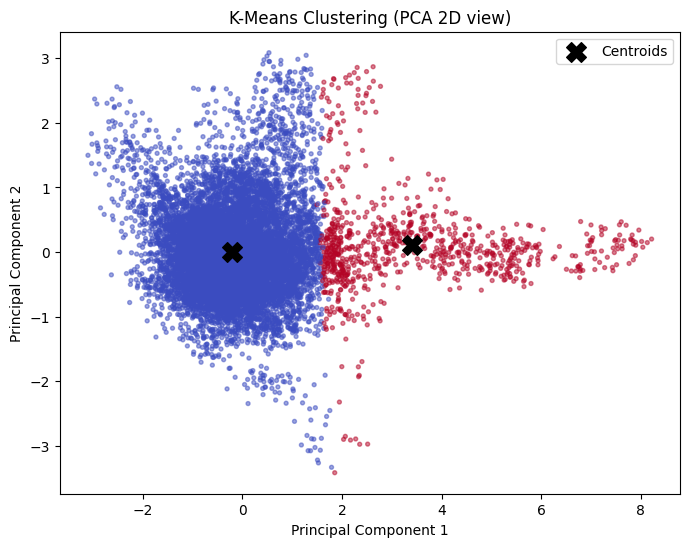

In [9]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_clean)
centers_pca = pca.transform(kmeans.cluster_centers_)

plt.figure(figsize=(8, 6))
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=clusters, cmap="coolwarm", s=8, alpha=0.5)
plt.scatter(centers_pca[:, 0], centers_pca[:, 1], c="black", marker="X", s=200, label="Centroids")
plt.title("K-Means Clustering (PCA 2D view)")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend()
plt.show()

## Conclusion
- K-Means split the EEG data into 2 clusters without seeing any labels.
- Accuracy against the true labels shows how well the clusters match eyes open / closed. It is modest because EEG signals overlap heavily, and K-Means is unsupervised.
- Scaling and outlier removal were needed because K-Means is distance-based and sensitive to extreme values.